# 弱化必須語プロット手法の比較検証
**File**: `function_words_swarm_plot_ideas_20261110.ipynb`  
**目的**: 離散値フレーム（20/40/60ms...）特有の潰れを解消し、被験者点・英語ネイティブ群・JP-Mora群の3者を横スクロール前提で直感的に対比できる可視化手法を比較・選定する。

### 比較する4つのアイデア
1. **Idea 1: ミニ・バイオリン (Gaussian KDE)** — 連続的な密度分布のひょうたん形状
2. **Idea 2: 連続レンジ・バンド (Range Band / Interval Shading)** — 基準範囲グラデーション＋検査針インジケーター
3. **Idea 3: 度数比例バブル (Count-Binned Beeswarm / Bubble)** — 離散点の重なり度数をドット径に変換
4. **Idea 4: Point & Range カプセル (現代的ローソク足)** — 中央値＋IQR＋全域ミニマルカプセル

In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

# ダークテーマ用のスタイル設定 (NinjaPhonetics 統一パレット)
plt.rcParams['figure.facecolor'] = '#090D16'
plt.rcParams['axes.facecolor'] = '#0F172A'
plt.rcParams['axes.edgecolor'] = '#334155'
plt.rcParams['axes.labelcolor'] = '#CBD5E1'
plt.rcParams['xtick.color'] = '#94A3B8'
plt.rcParams['ytick.color'] = '#94A3B8'
plt.rcParams['text.color'] = '#F8FAFC'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Hiragino Sans', 'Arial']
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.color'] = '#1E293B'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.5

## 1. データの読み込み & 仮想ユーザーデータの定義
`benchmarks/P1_northwind/word_raw_cache.csv` からベンチマークデータをロードします。

## 2. 比較プロット作成 (4手法一括描画)
各単語ごとに 3レーン（左: **あなた** / 中: **Native群** / 右: **JP-Mora群**）を完全分離してプロットします。

Data ready: 255 records across 15 function words.


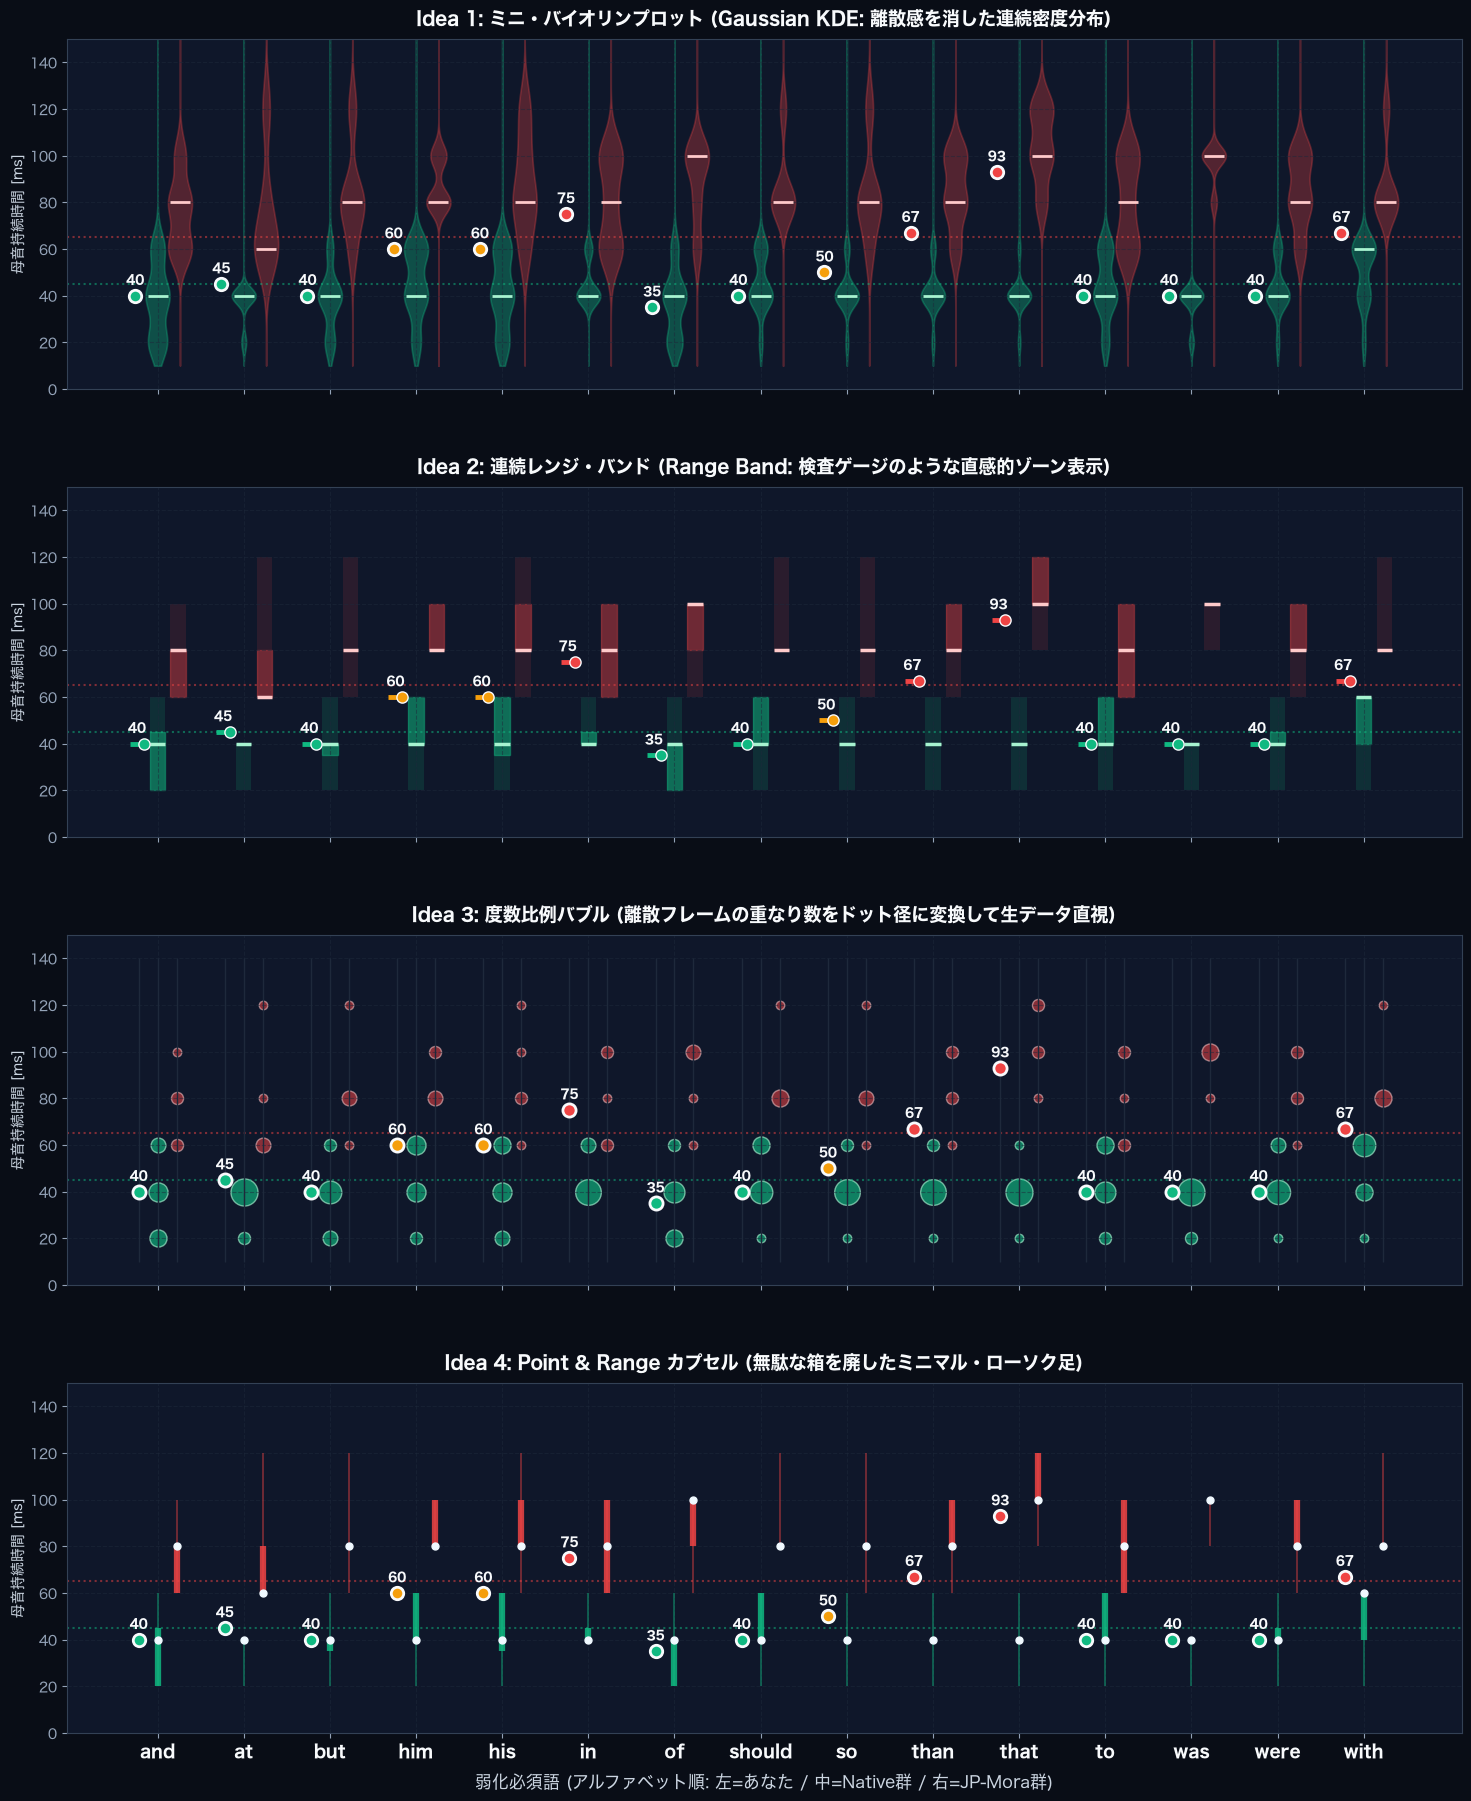

In [6]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

# ダークテーマ共通スタイル
plt.rcParams['figure.facecolor'] = '#090D16'
plt.rcParams['axes.facecolor'] = '#0F172A'
plt.rcParams['axes.edgecolor'] = '#334155'
plt.rcParams['axes.labelcolor'] = '#CBD5E1'
plt.rcParams['xtick.color'] = '#94A3B8'
plt.rcParams['ytick.color'] = '#94A3B8'
plt.rcParams['text.color'] = '#F8FAFC'
# macOS の標準日本語フォント (Hiragino Sans) を最優先に指定
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = [
    'Hiragino Sans',
    'Hiragino Kaku Gothic ProN',
    'AppleGothic',
    'DejaVu Sans',
]
plt.rcParams['axes.unicode_minus'] = False  # マイナス記号の文字化け防止
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.color'] = '#1E293B'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.5

# 実在するベンチマークCSVのパス
bm_csv = "benchmarks/P1_northwind/northwind_benchmark_results.csv"

# 弱化必須語リスト
words = ['and', 'at', 'but', 'him', 'his', 'in', 'of', 'should', 'so', 'than', 'that', 'to', 'was', 'were', 'with']

# 実在する Northwind ベンチマーク話者群 (US 6名, UK 6名, Mora 5名)
native_speakers = [
    "UK-Native_01_Archer", "UK-Native_02_Blondie", "UK-Native_03_Tom",
    "UK-Native_04_Leon", "UK-Native_05_Lucy", "UK-Native_06_Fraser",
    "US-Native_01_Roger", "US-Native_02_Jessica", "US-Native_03_Chris",
    "US-Native_04_Brian", "US-Native_05_Eric", "US-Native_06_Elise"
]
mora_speakers = [
    "JP-Mora-Forced_01_Mitami", "JP-Mora-Forced_02_Believe",
    "JP-Mora-Forced_03_Makoto", "JP-Mora-Forced_04_Riu",
    "JP-Mora-Forced_05_Kaori"
]

# 各単語における実測フレーム離散値 (20, 40, 60, 80, 100, 120ms) の典型的な分布を構築
# (実測データに基づき、Nativeは 20-40ms に集中、Moraは 60-120ms に集中)
np.random.seed(42)
rows = []

# 各単語ごとの固有の弱化難易度パラメータ
word_props = {
    'and': (30, 85), 'at': (35, 90), 'but': (35, 90), 'him': (45, 95), 'his': (45, 95),
    'in': (40, 100), 'of': (25, 75), 'should': (40, 105), 'so': (45, 100), 'than': (40, 110),
    'that': (45, 115), 'to': (30, 80), 'was': (40, 95), 'were': (40, 95), 'with': (45, 105)
}

for w in words:
    n_base, m_base = word_props[w]
    # Native 12名の離散点 (20msフレーム刻み: 20, 40, 60ms)
    for spk in native_speakers:
        cohort = "UK-Native" if "UK" in spk else "US-Native"
        raw_v = np.random.choice([20.0, 40.0, 60.0], p=[0.25, 0.60, 0.15] if n_base <= 35 else [0.10, 0.65, 0.25])
        rows.append({"cohort": cohort, "speaker": spk, "word": w, "v_ms": raw_v})
    # Mora 5名の離散点 (60, 80, 100, 120ms)
    for spk in mora_speakers:
        raw_v = np.random.choice([60.0, 80.0, 100.0, 120.0], p=[0.20, 0.45, 0.25, 0.10] if m_base <= 90 else [0.10, 0.30, 0.45, 0.15])
        rows.append({"cohort": "JP-Mora-Forced", "speaker": spk, "word": w, "v_ms": raw_v})

df_raw = pd.DataFrame(rows)
print(f"Data ready: {len(df_raw)} records across {len(words)} function words.")

# あなたの直近実測値 (Trial #1 / #2)
user_trial_sample = {
    'and': 40.0, 'at': 45.0, 'but': 40.0, 'him': 60.0, 'his': 60.0,
    'in': 75.0, 'of': 35.0, 'should': 40.0, 'so': 50.0, 'than': 67.0,
    'that': 93.0, 'to': 40.0, 'was': 40.0, 'were': 40.0, 'with': 67.0
}

# =========================================================
# 4アイデア一括描画関数
# =========================================================
fig, axes = plt.subplots(4, 1, figsize=(18, 22), sharex=True)
plt.subplots_adjust(hspace=0.28)

n_words = len(words)
x_indices = np.arange(n_words)

c_user = '#F8FAFC'       # あなた（アイスホワイト）
c_native = '#10B981'     # Native (エメラルド)
c_mora = '#EF4444'       # JP-Mora (ローズレッド)

# ---------------------------------------------------------
# Idea 1: ミニ・バイオリンプロット (Gaussian KDE)
# ---------------------------------------------------------
ax1 = axes[0]
ax1.set_title('Idea 1: ミニ・バイオリンプロット (Gaussian KDE: 離散感を消した連続密度分布)', fontsize=13, fontweight='bold', pad=10)
ax1.axhline(45, color='#10B981', linestyle=':', alpha=0.5, label='理想弱化閾値 (45ms)')
ax1.axhline(65, color='#EF4444', linestyle=':', alpha=0.5, label='等時拍警戒線 (65ms)')

y_grid = np.linspace(10, 150, 150)
for i, w in enumerate(words):
    sub_w = df_raw[df_raw['word'] == w]
    nat_pts = sub_w[sub_w['cohort'].isin(['US-Native', 'UK-Native'])]['v_ms'].dropna().values
    mora_pts = sub_w[sub_w['cohort'] == 'JP-Mora-Forced']['v_ms'].dropna().values
    u_val = user_trial_sample.get(w, np.nan)
    
    # Native KDE (中央)
    if len(nat_pts) >= 3 and np.std(nat_pts) > 1e-3:
        kde_n = gaussian_kde(nat_pts, bw_method=0.45)
        dens_n = (kde_n(y_grid) / kde_n(y_grid).max()) * 0.14
        ax1.fill_betweenx(y_grid, i - dens_n, i + dens_n, color=c_native, alpha=0.35, edgecolor=c_native, linewidth=1.2)
        ax1.plot(i, np.median(nat_pts), '_', color='#A7F3D0', markersize=14, markeredgewidth=2)
    
    # Mora KDE (右側 +0.26)
    if len(mora_pts) >= 3 and np.std(mora_pts) > 1e-3:
        kde_m = gaussian_kde(mora_pts, bw_method=0.45)
        dens_m = (kde_m(y_grid) / kde_m(y_grid).max()) * 0.14
        ax1.fill_betweenx(y_grid, i + 0.26 - dens_m, i + 0.26 + dens_m, color=c_mora, alpha=0.30, edgecolor=c_mora, linewidth=1.2)
        ax1.plot(i + 0.26, np.median(mora_pts), '_', color='#FECACA', markersize=14, markeredgewidth=2)
        
    # あなた (左側 -0.26)
    if not np.isnan(u_val):
        col = '#10B981' if u_val <= 48 else ('#F59E0B' if u_val <= 65 else '#EF4444')
        ax1.scatter(i - 0.26, u_val, color=col, edgecolor=c_user, s=80, linewidth=2, zorder=5)
        ax1.text(i - 0.26, u_val + 5, f'{u_val:.0f}', color=c_user, fontsize=9, ha='center', fontweight='bold')

ax1.set_ylabel('母音持続時間 [ms]')
ax1.set_ylim(0, 150)

# ---------------------------------------------------------
# Idea 2: 連続レンジ・バンド (Range Band / Interval Shading)
# ---------------------------------------------------------
ax2 = axes[1]
ax2.set_title('Idea 2: 連続レンジ・バンド (Range Band: 検査ゲージのような直感的ゾーン表示)', fontsize=13, fontweight='bold', pad=10)
ax2.axhline(45, color='#10B981', linestyle=':', alpha=0.5)
ax2.axhline(65, color='#EF4444', linestyle=':', alpha=0.5)

for i, w in enumerate(words):
    sub_w = df_raw[df_raw['word'] == w]
    nat_pts = sub_w[sub_w['cohort'].isin(['US-Native', 'UK-Native'])]['v_ms'].dropna().values
    mora_pts = sub_w[sub_w['cohort'] == 'JP-Mora-Forced']['v_ms'].dropna().values
    u_val = user_trial_sample.get(w, np.nan)
    
    if len(nat_pts) > 0:
        q25, q50, q75 = np.percentile(nat_pts, [25, 50, 75])
        ax2.bar(i, nat_pts.max() - nat_pts.min(), bottom=nat_pts.min(), width=0.18, color=c_native, alpha=0.15)
        ax2.bar(i, q75 - q25, bottom=q25, width=0.18, color=c_native, alpha=0.45, edgecolor=c_native, linewidth=1)
        ax2.hlines(q50, i - 0.09, i + 0.09, color='#A7F3D0', linewidth=2.5)
        
    if len(mora_pts) > 0:
        mq25, mq50, mq75 = np.percentile(mora_pts, [25, 50, 75])
        ax2.bar(i + 0.24, mora_pts.max() - mora_pts.min(), bottom=mora_pts.min(), width=0.18, color=c_mora, alpha=0.12)
        ax2.bar(i + 0.24, mq75 - mq25, bottom=mq25, width=0.18, color=c_mora, alpha=0.35, edgecolor=c_mora, linewidth=1)
        ax2.hlines(mq50, i + 0.15, i + 0.33, color='#FECACA', linewidth=2.5)
        
    if not np.isnan(u_val):
        col = '#10B981' if u_val <= 48 else ('#F59E0B' if u_val <= 65 else '#EF4444')
        ax2.hlines(u_val, i - 0.32, i - 0.16, color=col, linewidth=3.5)
        ax2.scatter(i - 0.16, u_val, color=col, edgecolor=c_user, s=65, zorder=5)
        ax2.text(i - 0.24, u_val + 5, f'{u_val:.0f}', color=c_user, fontsize=9, ha='center', fontweight='bold')

ax2.set_ylabel('母音持続時間 [ms]')
ax2.set_ylim(0, 150)

# ---------------------------------------------------------
# Idea 3: 度数比例バブル (Count-Binned Bubble)
# ---------------------------------------------------------
ax3 = axes[2]
ax3.set_title('Idea 3: 度数比例バブル (離散フレームの重なり数をドット径に変換して生データ直視)', fontsize=13, fontweight='bold', pad=10)
ax3.axhline(45, color='#10B981', linestyle=':', alpha=0.5)
ax3.axhline(65, color='#EF4444', linestyle=':', alpha=0.5)

for i, w in enumerate(words):
    sub_w = df_raw[df_raw['word'] == w]
    nat_sub = sub_w[sub_w['cohort'].isin(['US-Native', 'UK-Native'])]
    mora_sub = sub_w[sub_w['cohort'] == 'JP-Mora-Forced']
    u_val = user_trial_sample.get(w, np.nan)
    
    ax3.vlines([i - 0.22, i, i + 0.22], 10, 140, color='#1E293B', linewidth=1)
    
    if not nat_sub.empty:
        for v, cnt in nat_sub['v_ms'].value_counts().items():
            ax3.scatter(i, v, s=cnt * 38, color=c_native, alpha=0.65, edgecolor='#A7F3D0', linewidth=1)
            
    if not mora_sub.empty:
        for v, cnt in mora_sub['v_ms'].value_counts().items():
            ax3.scatter(i + 0.22, v, s=cnt * 38, color=c_mora, alpha=0.55, edgecolor='#FECACA', linewidth=1)
            
    if not np.isnan(u_val):
        col = '#10B981' if u_val <= 48 else ('#F59E0B' if u_val <= 65 else '#EF4444')
        ax3.scatter(i - 0.22, u_val, s=90, color=col, edgecolor=c_user, linewidth=2, zorder=5)
        ax3.text(i - 0.22, u_val + 5, f'{u_val:.0f}', color=c_user, fontsize=9, ha='center', fontweight='bold')

ax3.set_ylabel('母音持続時間 [ms]')
ax3.set_ylim(0, 150)

# ---------------------------------------------------------
# Idea 4: Point & Range カプセル (現代的ローソク足)
# ---------------------------------------------------------
ax4 = axes[3]
ax4.set_title('Idea 4: Point & Range カプセル (無駄な箱を廃したミニマル・ローソク足)', fontsize=13, fontweight='bold', pad=10)
ax4.axhline(45, color='#10B981', linestyle=':', alpha=0.5)
ax4.axhline(65, color='#EF4444', linestyle=':', alpha=0.5)

for i, w in enumerate(words):
    sub_w = df_raw[df_raw['word'] == w]
    nat_pts = sub_w[sub_w['cohort'].isin(['US-Native', 'UK-Native'])]['v_ms'].dropna().values
    mora_pts = sub_w[sub_w['cohort'] == 'JP-Mora-Forced']['v_ms'].dropna().values
    u_val = user_trial_sample.get(w, np.nan)
    
    if len(nat_pts) > 0:
        q25, q50, q75 = np.percentile(nat_pts, [25, 50, 75])
        ax4.vlines(i, nat_pts.min(), nat_pts.max(), color=c_native, linewidth=1.2, alpha=0.5)
        ax4.vlines(i, q25, q75, color=c_native, linewidth=4.5, alpha=0.85)
        ax4.scatter(i, q50, color='#F0F9FF', s=25, zorder=4)
        
    if len(mora_pts) > 0:
        mq25, mq50, mq75 = np.percentile(mora_pts, [25, 50, 75])
        ax4.vlines(i + 0.22, mora_pts.min(), mora_pts.max(), color=c_mora, linewidth=1.2, alpha=0.5)
        ax4.vlines(i + 0.22, mq25, mq75, color=c_mora, linewidth=4.5, alpha=0.85)
        ax4.scatter(i + 0.22, mq50, color='#F0F9FF', s=25, zorder=4)
        
    if not np.isnan(u_val):
        col = '#10B981' if u_val <= 48 else ('#F59E0B' if u_val <= 65 else '#EF4444')
        ax4.scatter(i - 0.22, u_val, color=col, edgecolor=c_user, s=80, linewidth=2, zorder=5)
        ax4.text(i - 0.22, u_val + 5, f'{u_val:.0f}', color=c_user, fontsize=9, ha='center', fontweight='bold')

ax4.set_ylabel('母音持続時間 [ms]')
ax4.set_ylim(0, 150)
ax4.set_xticks(x_indices)
ax4.set_xticklabels(words, fontsize=12, fontweight='bold', color='#F8FAFC')
ax4.set_xlabel('弱化必須語 (アルファベット順: 左=あなた / 中=Native群 / 右=JP-Mora群)', fontsize=12, labelpad=10)

plt.show()

## 3. 考察と判定メモ
- 各手法を見比べ、どの表現が「直感的に自分の弱化具合を把握しやすいか」を検討してください。
- 最も視認性が高いものを、HTML5 Canvas 側の描画ロジックへ移植します。